## Streaming real-time research to your Jupyter Notebook

#### Key Concepts
<ul>
<li>Use Flexreport Finance's Python client to subscribe topics</li>
<li>In this example, we subscribe to newly published research, which incorpotates breaking news, earnings announcements, financial disclousres, and big prices swings</li>
</ul>

In [2]:
import pypdfium2 as pdfium
import io
from IPython.display import display, Image, Markdown
from flexreportfinance import FlexreportClient

#### Fill these in

In [ ]:
file_path = "" 
email=""
pwd=""

#### A helper function to display research inline

In [5]:
def display_downloaded_report(full_file_path, max_pages=None, dpi=110):
      pdf = pdfium.PdfDocument(full_file_path)
      display(Markdown(f"### {full_file_path.split('/')[-1]} ({len(pdf)} pages)"))
      for i in range(min(len(pdf), max_pages or len(pdf))):
          buf = io.BytesIO()
          pdf[i].render(scale=dpi / 72).to_pil().save(buf, format="PNG")
          display(Image(data=buf.getvalue()))
      pdf.close()

#### Create a client and start streaming research

In [ ]:
with FlexreportClient(email, pwd) as client:
    for id, event in client.events.stream(topics=["report_plan"]):
        client.reports.download(symbols=[event.get("symbol")], file_directory=file_path)
        display_downloaded_report(full_file_path=f"{file_path}/{event.get('symbol')}.pdf", max_pages=None)  # Display the entire report


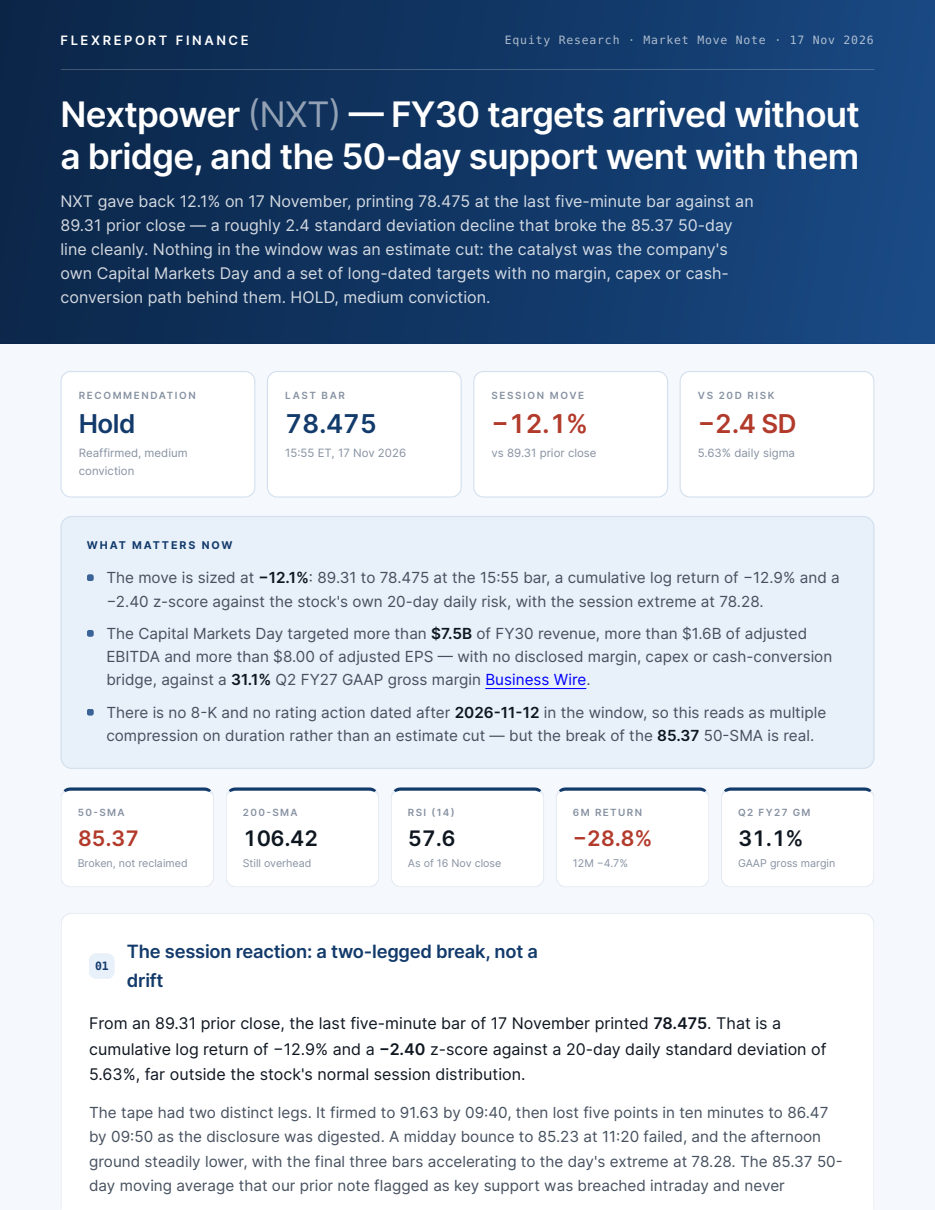

In [ ]:
import sys; print(sys.version)